# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
%pip install imbalanced-learn


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or X.shape[0] == 0:
            raise ValueError('X должна быть непустой двумерной матрицей')
        if y.shape != (X.shape[0],) or not np.all(np.isin(y, [0, 1])):
            raise ValueError('y должен быть вектором меток 0/1 длины N')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError("gd_type должен быть 'full' или 'stochastic'")
        if self.batch_size < 1:
            raise ValueError('batch_size должен быть положительным')

        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)
        self.n_features_in_ = X.shape[1]
        X = np.column_stack((np.ones(X.shape[0]), X))
        self.w = (np.zeros(X.shape[1]) if self.w0 is None
                  else np.asarray(self.w0, dtype=float).copy())
        if self.w.shape != (X.shape[1],):
            raise ValueError('w0 должен иметь размер d + 1')

        self.n_iter_ = 0
        for _ in range(self.max_iter):
            # Потери на всей выборке до очередного шага, включая первый.
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'full':
                gradient = self.calc_gradient(X, y)
            else:
                indices = rng.choice(
                    X.shape[0], size=min(self.batch_size, X.shape[0]),
                    replace=False)
                gradient = self.calc_gradient(X[indices], y[indices])

            w_new = self.w - self.eta * gradient
            weight_diff = np.linalg.norm(w_new - self.w)
            self.w = w_new
            self.n_iter_ += 1
            if weight_diff < self.tolerance:
                break

        return self

    def sigmoid(self, z):
        z = np.asarray(z, dtype=float)
        exp_neg_abs = np.exp(-np.abs(z))
        return np.where(z >= 0, 1 / (1 + exp_neg_abs),
                        exp_neg_abs / (1 + exp_neg_abs))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = np.asarray(X, dtype=float)
        X = np.column_stack((np.ones(X.shape[0]), X))
        p = self.sigmoid(X @ self.w)
        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        return X.T @ (self.sigmoid(X @ self.w) - y) / X.shape[0]

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        z = X @ self.w
        return float(np.mean(np.logaddexp(0, (1 - 2 * y) * z)))


Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 1.44e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

Полный спуск: 1000 итераций
Стохастический спуск: 1000 итераций


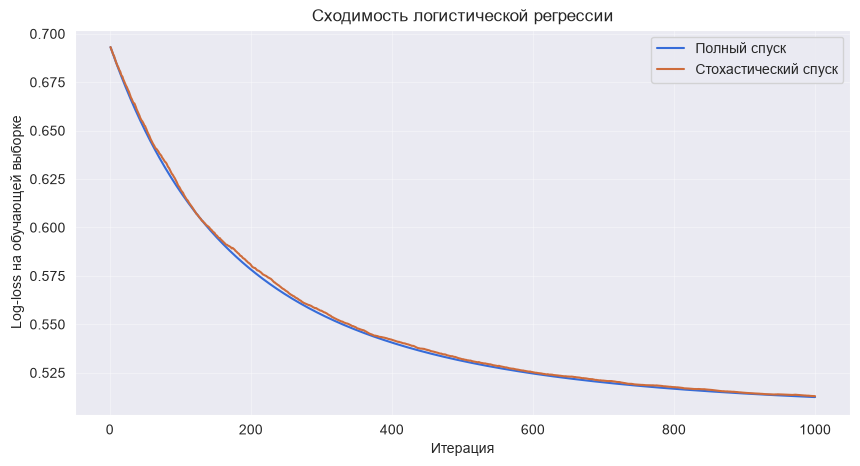

In [6]:
model_full = LogReg(gd_type='full').fit(X_train, y_train)
model_stochastic = LogReg(gd_type='stochastic').fit(X_train, y_train)

print(f"Полный спуск: {len(model_full.loss_history)} итераций")
print(f"Стохастический спуск: {len(model_stochastic.loss_history)} итераций")

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(model_full.loss_history) + 1),
         model_full.loss_history, label='Полный спуск')
plt.plot(np.arange(1, len(model_stochastic.loss_history) + 1),
         model_stochastic.loss_history, label='Стохастический спуск')
plt.xlabel('Итерация')
plt.ylabel('Log-loss на обучающей выборке')
plt.title('Сходимость логистической регрессии')
plt.legend()
plt.show()

Обе модели выполнили **1000 итераций** и остановились по ограничению `max_iter`.

При стохастическом спуске градиент зависит от случайного батча. Даже вблизи минимума он обычно не равен нулю, поэтому при постоянном шаге веса продолжают колебаться и условие `tolerance` может долго не выполняться.

Полный спуск даёт плавное снижение функции потерь. У стохастического спуска заметны небольшие колебания, но общий ход кривой похож. В конце потери составляют примерно **0.51245** и **0.51293** соответственно.

Для вычисления градиента полный спуск использует все **14 000** обучающих объектов на каждой итерации, а стохастический — **32** объекта. При этом в нашей реализации оба метода дополнительно вычисляют `loss_history` на всей обучающей выборке, поэтому каждый из них также просматривает все 14 000 объектов для расчёта потерь.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

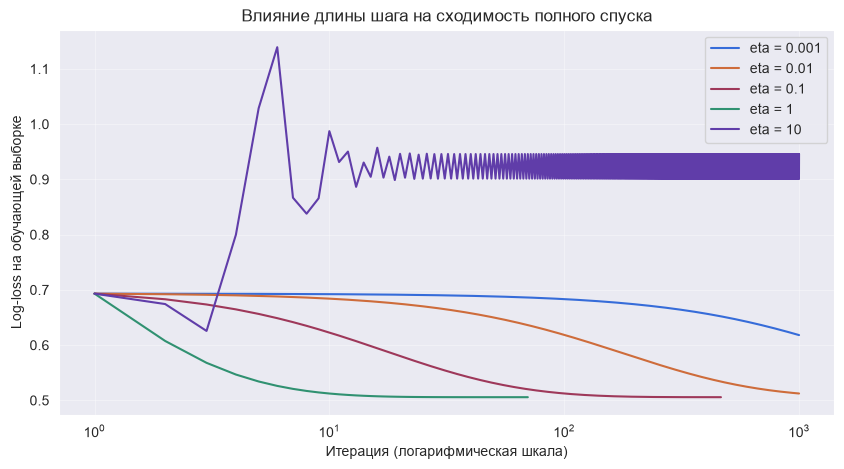

,eta,Финальный log-loss,Число итераций
0,0.001,0.618087,1000
1,0.010,0.512435,1000
2,0.100,0.505762,465
3,1.000,0.505757,70
4,10.000,0.901345,1000


In [7]:
eta_grid = [1e-3, 1e-2, 1e-1, 1, 10]
eta_results = []
X_train_bias = np.column_stack((np.ones(X_train.shape[0]), X_train))

plt.figure(figsize=(10, 5))
for eta in eta_grid:
    model = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    eta_results.append({
        'eta': eta,
        'Финальный log-loss': model.calc_loss(X_train_bias, y_train),
        'Число итераций': len(model.loss_history)
    })
    plt.plot(np.arange(1, len(model.loss_history) + 1),
             model.loss_history, label=f'eta = {eta:g}')

plt.xscale('log')
plt.xlabel('Итерация (логарифмическая шкала)')
plt.ylabel('Log-loss на обучающей выборке')
plt.title('Влияние длины шага на сходимость полного спуска')
plt.legend()
plt.show()

display(pd.DataFrame(eta_results))

При слишком маленьком шаге спуск сходится медленно: для `eta=0.001` даже за 1000 итераций потери снижаются только до **0.61809**. При `eta=0.01` за те же 1000 итераций получаем **0.51243**.

Увеличение шага до `0.1` и `1` ускоряет сходимость: модели останавливаются по `tolerance` за **465** и **70** итераций соответственно, достигая почти одинаковых потерь **0.50576**. Среди проверенных значений `eta=1` обеспечивает самую быструю устойчивую сходимость.

При `eta=10` шаг слишком большой: веса перескакивают через минимум, а потери колеблются вместо сходимости. Модель достигает `max_iter=1000` с потерями около **0.90135**, что хуже начального значения **0.69315**. Таким образом, увеличение шага полезно лишь до определённого предела.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
model_sklearn = LogisticRegression().fit(X_train, y_train)

comparison = []
for name, fitted_model in [('GD', model_full),
                           ('SGD', model_stochastic),
                           ('sklearn', model_sklearn)]:
    y_pred = fitted_model.predict(X_test)
    y_proba = fitted_model.predict_proba(X_test)[:, 1]
    comparison.append({
        'Модель': name,
        'Accuracy': metrics.accuracy_score(y_test, y_pred),
        'ROC-AUC': metrics.roc_auc_score(y_test, y_proba)
    })

display(pd.DataFrame(comparison).set_index('Модель'))

weights_sklearn = np.concatenate(
    (model_sklearn.intercept_, model_sklearn.coef_.ravel()))
weights_comparison = pd.DataFrame({
    'GD': model_full.w,
    'sklearn': weights_sklearn,
    'Разность (GD - sklearn)': model_full.w - weights_sklearn
}, index=['w0'] + [f'w{i}' for i in range(1, X_train.shape[1] + 1)])

display(weights_comparison)
print(f'L2-норма разности весов: '
      f'{np.linalg.norm(model_full.w - weights_sklearn):.6f}')

,Accuracy,ROC-AUC
Модель,,
GD,0.7820,0.838787
SGD,0.7825,0.838115
sklearn,0.7765,0.838676


,GD,sklearn,Разность (GD - sklearn)
w0,-0.002114,-0.021880,0.019765
w1,0.006076,0.002741,0.003335
w2,0.006963,0.009039,-0.002077
w3,-0.547170,-0.722690,0.175520
w4,-0.144536,-0.262335,0.117799
w5,0.012487,0.016588,-0.004102
w6,-0.006325,-0.011488,0.005163
w7,0.000814,0.005587,-0.004773
w8,0.039084,0.057188,-0.018104
w9,-0.002425,-0.001239,-0.001185


L2-норма разности весов: 0.356783


Метрики близки, но не совпадают: accuracy составляет **0.7820** для GD, **0.7825** для SGD и **0.7765** для `sklearn`; ROC-AUC — примерно **0.83879**, **0.83812** и **0.83868** соответственно. Небольшое преимущество GD по accuracy на этой тестовой выборке не означает, что его функция потерь лучше оптимизирована.

Веса также различаются: L2-норма разности векторов GD и `sklearn`, включая свободный член, равна примерно **0.35678**. Наш GD с шагом по умолчанию остановился на 1000 итерациях, ещё не достигнув минимума, что видно из задания 1.3. Кроме того, различаются методы оптимизации: у `sklearn` по умолчанию используется `lbfgs`.

В `LogisticRegression` по умолчанию применяется **L2-регуляризация** с `C=1`, тогда как наш класс минимизирует log-loss без регуляризации. Для той же задачи оптимизации в установленной версии `sklearn` можно использовать:

```python
LogisticRegression(C=np.inf, solver='lbfgs', fit_intercept=True,
                   max_iter=1000, tol=1e-8)
```

`C=np.inf` отключает регуляризацию. В предыдущих версиях для этого задавали `penalty=None`; с версии 1.8 параметр `penalty` объявлен устаревшим. Увеличение `max_iter` и уменьшение `tol` позволяют точнее решить задачу, но сами по себе не меняют её целевую функцию. Даже при одинаковой задаче результаты могут немного различаться из-за алгоритмов и критериев остановки.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
df = pd.read_csv('wine_quality.csv')

print('Data shape:', df.shape)
df.head()

Data shape: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (4547, 12)  Test: (1950, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('Пропуски по столбцам:')
display(df.isna().sum().to_frame('Число пропусков'))
print('Полных дубликатов строк:', df.duplicated().sum())
print(f'Prevalence train: {y_train.mean():.4f}')
print(f'Prevalence test:  {y_test.mean():.4f}')

wine_model = make_pipeline(StandardScaler(), LogisticRegression())
wine_model.fit(X_train, y_train)
y_pred_wine = wine_model.predict(X_test)
display(pd.DataFrame({
    'Модель': ['Всегда класс 0', 'Логистическая регрессия'],
    'Accuracy': [
        metrics.accuracy_score(y_test, np.zeros(len(y_test), dtype=int)),
        metrics.accuracy_score(y_test, y_pred_wine)
    ]
}))

Пропуски по столбцам:


,Число пропусков
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


Полных дубликатов строк: 1177
Prevalence train: 0.1966
Prevalence test:  0.1964


,Модель,Accuracy
0,Всегда класс 0,0.80359
1,Логистическая регрессия,0.82000


Пропусков нет. Найдено **1177 полных повторов строк**. Автоматически удалять их только из-за совпадения значений не обязательно: это могут быть разные образцы с одинаковыми округлёнными характеристиками. В рамках задания сохраняем исходные данные и заданное разбиение. Если это повторные записи одного образца, их следует удалить до разбиения или разделять по группам образцов: иначе одинаковые наблюдения могут оказаться в train и test и завысить оценку качества. По имеющимся столбцам однозначно установить происхождение повторов нельзя.

Доля хороших вин составляет **19.66%** в train и **19.64%** в test. `stratify=y` сохраняет примерно одинаковые доли классов в обеих выборках.

Константная модель получает accuracy **0.8036**, а логистическая регрессия — **0.8200**. Даже модель, не находящая ни одного хорошего вина, имеет высокую accuracy благодаря большинству класса 0. Эта метрика не показывает отдельно качество отбора хороших вин и число пропусков, поэтому нужны precision, recall и F-меры.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=98, TN=1501, FP=66, FN=285
Матрицы совпадают: True


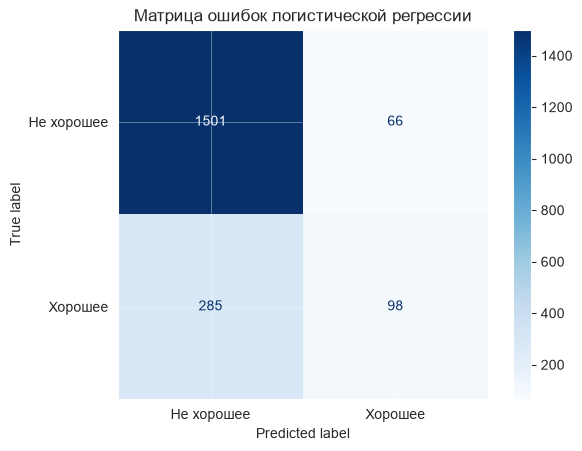

In [12]:
y_true = np.asarray(y_test)
y_pred_wine = wine_model.predict(X_test)
TP = int(np.sum((y_true == 1) & (y_pred_wine == 1)))
TN = int(np.sum((y_true == 0) & (y_pred_wine == 0)))
FP = int(np.sum((y_true == 0) & (y_pred_wine == 1)))
FN = int(np.sum((y_true == 1) & (y_pred_wine == 0)))
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')

cm_manual = np.array([[TN, FP], [FN, TP]])
cm_sklearn = metrics.confusion_matrix(y_test, y_pred_wine, labels=[0, 1])
print('Матрицы совпадают:', np.array_equal(cm_manual, cm_sklearn))
assert np.array_equal(cm_manual, cm_sklearn)
metrics.ConfusionMatrixDisplay(
    confusion_matrix=cm_manual,
    display_labels=['Не хорошее', 'Хорошее']
).plot(cmap='Blues')
plt.title('Матрица ошибок логистической регрессии')
plt.show()

Получены **TP=98, TN=1501, FP=66, FN=285**. Ручной расчёт совпал с `sklearn`.

**FP** — посредственное вино, которое модель посчитала хорошим и включила в подборку: клиент может разочароваться. **FN** — хорошее вино, которое модель отклонила: подборка становится беднее.

Чаще встречаются **FN: 285 против 66 FP**. При пороге 0.5 модель пропускает большую часть хороших вин.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0

def fbeta_manual(precision, recall, beta):
    denominator = beta ** 2 * precision + recall
    return ((1 + beta ** 2) * precision * recall / denominator
            if denominator else 0.0)

manual_scores = np.array([
    precision, recall, fbeta_manual(precision, recall, 1),
    fbeta_manual(precision, recall, 0.5), fbeta_manual(precision, recall, 2)
])
sklearn_scores = np.array([
    metrics.precision_score(y_test, y_pred_wine, zero_division=0),
    metrics.recall_score(y_test, y_pred_wine, zero_division=0),
    metrics.fbeta_score(y_test, y_pred_wine, beta=1, zero_division=0),
    metrics.fbeta_score(y_test, y_pred_wine, beta=0.5, zero_division=0),
    metrics.fbeta_score(y_test, y_pred_wine, beta=2, zero_division=0)
])
display(pd.DataFrame({
    'По формулам': manual_scores, 'sklearn': sklearn_scores
}, index=['Precision', 'Recall', 'F1', 'F0.5', 'F2']))
assert np.allclose(manual_scores, sklearn_scores)

,По формулам,sklearn
Precision,0.597561,0.597561
Recall,0.255875,0.255875
F1,0.358318,0.358318
F0.5,0.471607,0.471607
F2,0.288915,0.288915


Ручной расчёт и `sklearn` совпали: precision ≈ **0.5976**, recall ≈ **0.2559**, F1 ≈ **0.3583**, F0.5 ≈ **0.4716**, F2 ≈ **0.2889**.

В **F0.5** больший вес имеет precision, в **F2** — recall, а **F1** учитывает их симметрично.

Если клиенты болезненно реагируют на посредственные вина, выбрал бы **F0.5**: важна высокая доля действительно хороших вин среди рекомендованных. Для «самой широкой подборки хороших вин» выбрал бы **F2**, чтобы меньше хороших образцов оставалось за пределами подборки. F1 подходит как компромисс, если приоритеты не заданы.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

GD: 5323 итераций; норма следующего шага: 1.00e-04


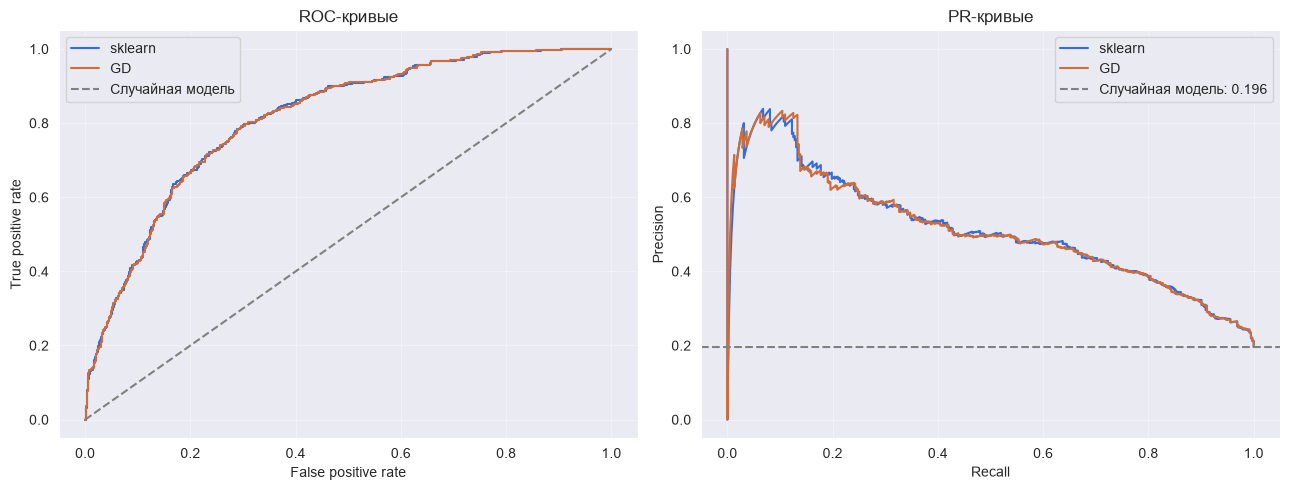

,ROC-AUC,PR-AUC (average precision)
Модель,,
sklearn,0.813537,0.512104
GD,0.813107,0.512486


,Оценка,ROC-AUC
0,p,0.813537
1,10 * p,0.813537
2,p ** 3,0.813537
3,log(p / (1 - p)),0.813537
4,-p,0.186463


ROC-AUC по меткам: 0.6068779877399565


In [14]:
wine_scaler = StandardScaler()
X_train_scaled = wine_scaler.fit_transform(X_train)
X_test_scaled = wine_scaler.transform(X_test)
wine_gd = LogReg(gd_type='full', eta=0.1, max_iter=20000,
                 tolerance=1e-4).fit(X_train_scaled, y_train.to_numpy())
train_bias = np.column_stack((np.ones(len(X_train)), X_train_scaled))
step_norm = wine_gd.eta * np.linalg.norm(
    wine_gd.calc_gradient(train_bias, y_train.to_numpy()))
print(f'GD: {wine_gd.n_iter_} итераций; норма следующего шага: {step_norm:.2e}')
assert step_norm < wine_gd.tolerance, 'Увеличьте max_iter для сходимости'

p_sklearn = wine_model.predict_proba(X_test)[:, 1]
p_gd = wine_gd.predict_proba(X_test_scaled)[:, 1]
curve_results = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, scores in [('sklearn', p_sklearn), ('GD', p_gd)]:
    fpr, tpr, _ = metrics.roc_curve(y_test, scores)
    pr_precision, pr_recall, _ = metrics.precision_recall_curve(y_test, scores)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(pr_recall, pr_precision, label=name)
    curve_results.append({
        'Модель': name,
        'ROC-AUC': metrics.roc_auc_score(y_test, scores),
        'PR-AUC (average precision)': metrics.average_precision_score(y_test, scores)
    })
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Случайная модель')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate',
            title='ROC-кривые')
axes[1].axhline(y_test.mean(), linestyle='--', color='gray',
                label=f'Случайная модель: {y_test.mean():.3f}')
axes[1].set(xlabel='Recall', ylabel='Precision', title='PR-кривые')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(curve_results).set_index('Модель'))

p_clipped = np.clip(p_sklearn, 1e-15, 1 - 1e-15)
transformed_scores = {
    'p': p_sklearn,
    '10 * p': 10 * p_sklearn,
    'p ** 3': p_sklearn ** 3,
    'log(p / (1 - p))': np.log(p_clipped / (1 - p_clipped)),
    '-p': -p_sklearn
}
display(pd.DataFrame([
    {'Оценка': name, 'ROC-AUC': metrics.roc_auc_score(y_test, scores)}
    for name, scores in transformed_scores.items()
]))
print('ROC-AUC по меткам:', metrics.roc_auc_score(y_test, y_pred_wine))

Собственный GD сошёлся по `tolerance` за **5323 итерации** при `eta=0.1`. Масштабирование обучено только на train.

По **ROC-AUC** немного лучше `sklearn`: **0.81354** против **0.81311**. По **PR-AUC (average precision)** немного лучше GD: **0.51249** против **0.51210**. Ранжирование не совпало, но различия очень малы; по одной тестовой выборке нельзя говорить об убедительном превосходстве одной модели. Для качества отбора редкого положительного класса особенно полезна PR-кривая.

Базовый уровень precision случайного отбора равен доле положительного класса: **383 / 1950 ≈ 0.1964**. Это и есть ориентир PR-AUC случайной модели, а не 0.5: среди случайно выбранных вин примерно 19.64% хороших. Для конечной случайной выборки average precision может немного отличаться от этого ориентира.

Преобразования `10*p`, `p**3` и `log(p/(1-p))` строго возрастают и сохраняют порядок объектов, поэтому ROC-AUC остаётся **0.81354**. Значения score не обязаны лежать в [0, 1]. Преобразование `-p` обращает порядок и даёт **1 − AUC ≈ 0.18646**.

Если передать метки 0/1, функция всё равно посчитает ROC-AUC, но ранжирование внутри двух групп потеряется. Получаем только одну содержательную точку ROC-кривой и **AUC ≈ 0.60688**, равный в бинарном случае `(TPR + TNR) / 2`. Поэтому для оценки ранжирования следует передавать непрерывные оценки.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

,Правило,Порог,Precision на валидации,Recall на валидации,F1 на валидации
0,Максимум F1,0.268889,0.460123,0.669643,0.545455
1,Максимум precision при recall >= 0.7,0.243196,0.438547,0.700893,0.539519


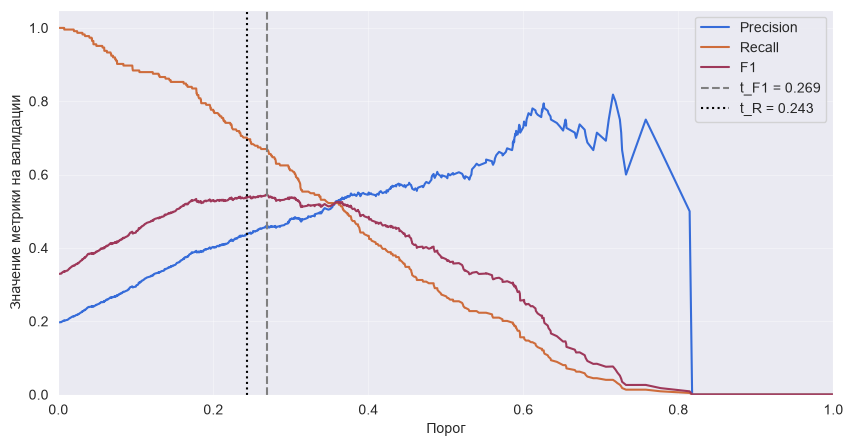

,Порог,Precision,Recall,F1
Правило,,,,
0.5,0.500000,0.597561,0.255875,0.358318
t_F1,0.268889,0.473888,0.639687,0.544444
t_R,0.243196,0.436975,0.678851,0.531697


In [15]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train,
    random_state=RANDOM_STATE)
threshold_model = make_pipeline(StandardScaler(), LogisticRegression())
threshold_model.fit(X_fit, y_fit)
p_val = threshold_model.predict_proba(X_val)[:, 1]

# Все различные варианты предсказаний на валидации плюс границы [0, 1].
thresholds = np.unique(np.r_[0.0, p_val, 1.0])
val_predictions = p_val[:, None] >= thresholds[None, :]
val_positive = y_val.to_numpy()[:, None] == 1
tp_val = np.sum(val_predictions & val_positive, axis=0)
fp_val = np.sum(val_predictions & ~val_positive, axis=0)
fn_val = np.sum(~val_predictions & val_positive, axis=0)
precision_val = np.divide(tp_val, tp_val + fp_val,
                          out=np.zeros_like(thresholds), where=(tp_val + fp_val) > 0)
recall_val = tp_val / np.sum(val_positive)
f1_val = np.divide(2 * tp_val, 2 * tp_val + fp_val + fn_val,
                   out=np.zeros_like(thresholds),
                   where=(2 * tp_val + fp_val + fn_val) > 0)

best_f1_idx = np.argmax(f1_val)
eligible = np.flatnonzero(recall_val >= 0.7)
best_recall_idx = eligible[np.argmax(precision_val[eligible])]
t_f1 = thresholds[best_f1_idx]
t_r = thresholds[best_recall_idx]
display(pd.DataFrame({
    'Правило': ['Максимум F1', 'Максимум precision при recall >= 0.7'],
    'Порог': [t_f1, t_r],
    'Precision на валидации': precision_val[[best_f1_idx, best_recall_idx]],
    'Recall на валидации': recall_val[[best_f1_idx, best_recall_idx]],
    'F1 на валидации': f1_val[[best_f1_idx, best_recall_idx]]
}))

plt.figure(figsize=(10, 5))
plt.plot(thresholds, precision_val, label='Precision')
plt.plot(thresholds, recall_val, label='Recall')
plt.plot(thresholds, f1_val, label='F1')
plt.axvline(t_f1, color='gray', linestyle='--', label=f't_F1 = {t_f1:.3f}')
plt.axvline(t_r, color='black', linestyle=':', label=f't_R = {t_r:.3f}')
plt.xlabel('Порог')
plt.ylabel('Значение метрики на валидации')
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.show()

# Пороги зафиксированы. Переобучаемся на всём train и оцениваем test.
threshold_model.fit(X_train, y_train)
p_test_threshold = threshold_model.predict_proba(X_test)[:, 1]
threshold_results = []
for name, threshold in [('0.5', 0.5), ('t_F1', t_f1), ('t_R', t_r)]:
    predictions = (p_test_threshold >= threshold).astype(int)
    threshold_results.append({
        'Правило': name, 'Порог': threshold,
        'Precision': metrics.precision_score(y_test, predictions, zero_division=0),
        'Recall': metrics.recall_score(y_test, predictions, zero_division=0),
        'F1': metrics.f1_score(y_test, predictions, zero_division=0)
    })
display(pd.DataFrame(threshold_results).set_index('Правило'))

На валидации выбраны **t_F1 ≈ 0.26889** и **t_R ≈ 0.24320**. Первый максимизирует F1, второй — precision среди порогов с recall ≥ 0.7. Для t_R на валидации recall ≈ **0.7009** и precision ≈ **0.4385**. Пороги выбраны без использования тестовой выборки.

После переобучения на всём train на тесте:

- **0.5:** precision ≈ 0.5976, recall ≈ 0.2559, F1 ≈ 0.3583;
- **t_F1:** precision ≈ 0.4739, recall ≈ 0.6397, F1 ≈ 0.5444;
- **t_R:** precision ≈ 0.4370, recall ≈ 0.6789, F1 ≈ 0.5317.

Условие **recall ≥ 0.7 на тесте не выполнилось**. Валидация даёт выборочную оценку, а не гарантию: состав новых данных отличается, и после переобучения изменились вероятности модели. Особенно ненадёжен порог, при котором ограничение выполняется почти без запаса.

Если требование охватить не менее 70% хороших вин является приоритетом сервиса, из рассмотренных правил выбрал бы **t_R**, поскольку именно оно учитывает это требование при выборе на валидации. Его нельзя считать гарантией, а precision около 44% означает много посредственных рекомендаций. Если жёсткого ограничения на recall нет, для компромисса между разнообразием и качеством выбрал бы **t_F1**. Если важнее всего не разочаровывать подписчиков, нужно отдельно выбрать по валидации порог с приоритетом precision, например по F0.5. Подгонять порог по полученным тестовым результатам нельзя.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
def evaluate_wine_model(name, fitted_model, threshold=0.5, X_eval=None, y_eval=None):
    if X_eval is None:
        X_eval = X_test
    if y_eval is None:
        y_eval = y_test
    scores = fitted_model.predict_proba(X_eval)[:, 1]
    predictions = (scores >= threshold).astype(int)
    return {
        'Модель': name, 'Порог': threshold,
        'Accuracy': metrics.accuracy_score(y_eval, predictions),
        'Precision': metrics.precision_score(y_eval, predictions, zero_division=0),
        'Recall': metrics.recall_score(y_eval, predictions, zero_division=0),
        'F1': metrics.f1_score(y_eval, predictions, zero_division=0),
        'ROC-AUC': metrics.roc_auc_score(y_eval, scores),
        'PR-AUC': metrics.average_precision_score(y_eval, scores)
    }

class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (2 * class_counts)
display(pd.DataFrame({'Число объектов': class_counts, 'Вес balanced': class_weights}))

model_unweighted = make_pipeline(
    StandardScaler(), LogisticRegression(class_weight=None, random_state=RANDOM_STATE))
model_balanced = make_pipeline(
    StandardScaler(), LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE))
model_unweighted.fit(X_train, y_train)
model_balanced.fit(X_train, y_train)
part3_results = [
    evaluate_wine_model('Без весов', model_unweighted),
    evaluate_wine_model('balanced', model_balanced)
]
display(pd.DataFrame(part3_results).set_index('Модель'))

,Число объектов,Вес balanced
target,,
0,3653,0.622365
1,894,2.543065


,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Модель,,,,,,,
Без весов,0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532


По формуле из [документации sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) вес класса равен `N / (K * N_k)`. В train **4547** объектов: **3653** класса 0 и **894** класса 1. Поэтому веса равны **0.6224** и **2.5431** соответственно. Суммарный вес каждого класса одинаков, а ошибка на хорошем вине получает примерно в 4.09 раза больший вес, чем ошибка на посредственном.

С `balanced` recall вырос с **0.2559** до **0.7546**, F1 — с **0.3583** до **0.5203**. При этом precision снизился с **0.5976** до **0.3970**, accuracy — с **0.8200** до **0.7267**. Модель чаще рекомендует вино, находит больше хороших образцов, но допускает больше ложных рекомендаций.

ROC-AUC изменился мало: **0.8135 → 0.8113**; PR-AUC также близок: **0.5121 → 0.5005**. Значительно изменилось решение при фиксированном пороге 0.5, а общее качество ранжирования осталось похожим.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {
    'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
    'NearMiss-2': NearMiss(version=2),
    'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
    'SMOTE': SMOTE(random_state=RANDOM_STATE)
}
resampling_models = {}
resampling_results = []
resampled_counts = []

for name, sampler in samplers.items():
    pipeline = make_imblearn_pipeline(
        StandardScaler(), sampler,
        LogisticRegression(random_state=RANDOM_STATE))
    pipeline.fit(X_train, y_train)
    resampling_models[name] = pipeline
    resampling_results.append(evaluate_wine_model(name, pipeline))
    fitted_sampler = pipeline.steps[1][1]
    if hasattr(fitted_sampler, 'sample_indices_'):
        counts = y_train.iloc[fitted_sampler.sample_indices_].value_counts()
    else:
        # У SMOTE sampling_strategy_ содержит число добавленных объектов.
        counts = class_counts.copy()
        for label, added in fitted_sampler.sampling_strategy_.items():
            counts.loc[label] += added
    resampled_counts.append({
        'Метод': name, 'Класс 0': int(counts.loc[0]), 'Класс 1': int(counts.loc[1])
    })

display(pd.DataFrame(resampled_counts).set_index('Метод'))
display(pd.DataFrame(part3_results + resampling_results).set_index('Модель'))

# Проверяем влияние порядка на NearMiss-2.
nearmiss_before_scaling = make_imblearn_pipeline(
    NearMiss(version=2), StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE))
nearmiss_before_scaling.fit(X_train, y_train)
order_results = [
    evaluate_wine_model('Scaler → NearMiss-2', resampling_models['NearMiss-2']),
    evaluate_wine_model('NearMiss-2 → Scaler', nearmiss_before_scaling)
]
display(pd.DataFrame(order_results).set_index('Модель'))
indices_scaled = resampling_models['NearMiss-2'].steps[1][1].sample_indices_
indices_raw = nearmiss_before_scaling.steps[0][1].sample_indices_
print('Совпадают выбранные строки:',
      np.array_equal(np.sort(indices_scaled), np.sort(indices_raw)))

,Класс 0,Класс 1
Метод,,
RandomUnderSampler,894,894
NearMiss-2,894,894
RandomOverSampler,3653,3653
SMOTE,3653,3653


,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Модель,,,,,,,
Без весов,0.5,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
balanced,0.5,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532
RandomUnderSampler,0.5,0.729744,0.401099,0.762402,0.525653,0.809354,0.500779
NearMiss-2,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
RandomOverSampler,0.5,0.726667,0.397260,0.757180,0.521114,0.811484,0.500216
SMOTE,0.5,0.729231,0.399166,0.749347,0.520871,0.812465,0.503980


,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Модель,,,,,,,
Scaler → NearMiss-2,0.5,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
NearMiss-2 → Scaler,0.5,0.681026,0.351183,0.736292,0.475548,0.755049,0.393364


Совпадают выбранные строки: False


После undersampling у RandomUnderSampler и NearMiss-2 осталось по **894** объекта каждого класса. RandomOverSampler и SMOTE увеличили меньший класс до **3653** объектов, поэтому оба класса содержат по 3653 наблюдения.

Нужен [пайплайн imblearn](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html), поскольку он поддерживает `fit_resample`, меняющий число объектов и метки. Обычный пайплайн sklearn ожидает промежуточные преобразования признаков через `transform`. При `predict` ресемплер пропускается: тест проходит масштабирование и классификатор, число тестовых объектов и их распределение сохраняются.

Балансировать весь датасет до разбиения нельзя: копии одного наблюдения могут попасть в train и test, а синтетические точки и отбор соседей могут использовать информацию из будущего test. Кроме утечки, балансировка test изменит доли классов и исказит оценку качества на реальном распределении.

Среди четырёх основных методов ресемплинга лучший **PR-AUC у SMOTE: 0.5040**, худший — у **NearMiss-2: 0.4001**. Возможное объяснение: SMOTE сохраняет исходные наблюдения и добавляет точки меньшего класса, а NearMiss удаляет большую часть класса 0 и сильно меняет его распределение. Это объяснение результата эксперимента, а не доказательство превосходства SMOTE в других задачах. Базовая модель без ресемплинга здесь получила PR-AUC **0.5121**.

**NearMiss и SMOTE зависят от расстояний**, поэтому масштабирование влияет на выбор соседей, отобранные или сгенерированные точки. **RandomUnderSampler и RandomOverSampler выбирают строки случайно**, поэтому при фиксированном seed сами индексы выборки не зависят от масштаба. Однако порядок может изменить итоговую модель даже у них: StandardScaler будет оценивать средние и дисперсии по разным выборкам, что влияет на регуляризованную регрессию.

Проверка NearMiss-2 показала, что выбранные строки различаются. При порядке «Scaler → NearMiss» ROC-AUC ≈ **0.7399**, PR-AUC ≈ **0.4001**; при обратном порядке — **0.7550** и **0.3934**. Изменились и прочие метрики. Выбирать порядок по test не следует; здесь это предусмотренный заданием сравнительный эксперимент.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Модель,,,,,,,
"balanced, t=0.5",0.500000,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532
"Без весов, t_F1",0.268889,0.789744,0.473888,0.639687,0.544444,0.813537,0.512104


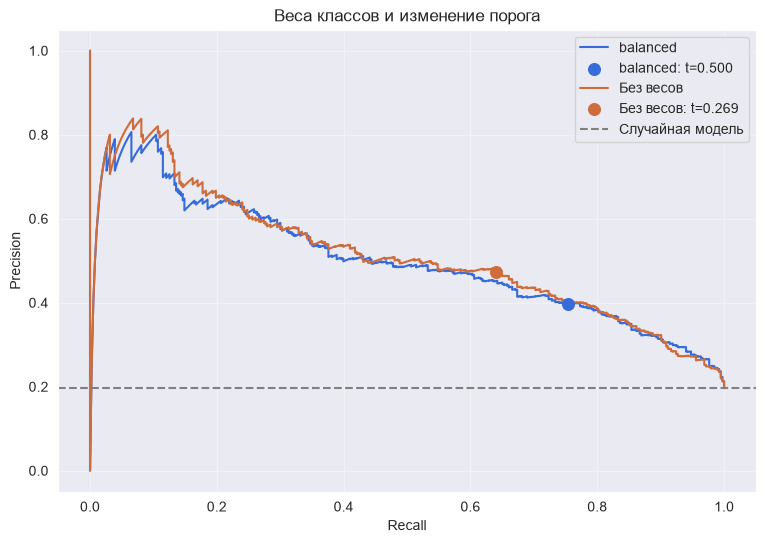

In [18]:
threshold_comparison = [
    evaluate_wine_model('balanced, t=0.5', model_balanced),
    evaluate_wine_model('Без весов, t_F1', model_unweighted, threshold=t_f1)
]
display(pd.DataFrame(threshold_comparison).set_index('Модель'))

plt.figure(figsize=(9, 6))
for name, fitted_model, threshold in [
    ('balanced', model_balanced, 0.5),
    ('Без весов', model_unweighted, t_f1)
]:
    scores = fitted_model.predict_proba(X_test)[:, 1]
    pr_precision, pr_recall, _ = metrics.precision_recall_curve(y_test, scores)
    plt.plot(pr_recall, pr_precision, label=name)
    predictions = scores >= threshold
    point_precision = metrics.precision_score(y_test, predictions, zero_division=0)
    point_recall = metrics.recall_score(y_test, predictions, zero_division=0)
    plt.scatter(point_recall, point_precision, s=70,
                label=f'{name}: t={threshold:.3f}', zorder=3)

plt.axhline(y_test.mean(), color='gray', linestyle='--', label='Случайная модель')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Веса классов и изменение порога')
plt.legend()
plt.show()

PR-кривые расположены близко, но не совпадают. PR-AUC составляет **0.5005** у `balanced` и **0.5121** у модели без весов.

При пороге **0.5** у `balanced` precision ≈ **0.3970**, recall ≈ **0.7546**, F1 ≈ **0.5203**. У модели без весов с порогом **t_F1 ≈ 0.2689** precision ≈ **0.4739**, recall ≈ **0.6397**, F1 ≈ **0.5444**. Точки на графике отражают разные компромиссы между точностью и полнотой.

В этом эксперименте взвешивание в основном меняет рабочую точку: повышает оценки положительного класса и делает порог 0.5 менее строгим относительно исходной модели. Однако это **не точный эквивалент смены порога**: веса меняют задачу обучения и коэффициенты, поэтому может измениться ранжирование. Смена порога у уже обученной модели ранжирование и всю PR-кривую сохраняет.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
from sklearn.dummy import DummyClassifier

constant_model = DummyClassifier(strategy='constant', constant=0).fit(X_train, y_train)
# Масштабирование и GD уже обучены в задании 2.4.
wine_gd_pipeline = make_pipeline(wine_scaler, wine_gd)
all_results = [
    evaluate_wine_model('Всегда класс 0', constant_model),
    evaluate_wine_model('Без весов, t=0.5', model_unweighted),
    evaluate_wine_model('Собственный GD', wine_gd_pipeline),
    evaluate_wine_model('Без весов, t_F1', model_unweighted, threshold=t_f1),
    evaluate_wine_model('Без весов, t_R', model_unweighted, threshold=t_r),
    evaluate_wine_model('balanced', model_balanced)
] + resampling_results + [order_results[1]]

all_models_table = pd.DataFrame(all_results).set_index('Модель')
display(all_models_table)

# Порог выбран на валидации в 2.5, тест используется для отчёта о качестве.
final_model = model_unweighted
final_threshold = t_f1

,Порог,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Модель,,,,,,,
Всегда класс 0,0.500000,0.803590,0.000000,0.000000,0.000000,0.500000,0.196410
"Без весов, t=0.5",0.500000,0.820000,0.597561,0.255875,0.358318,0.813537,0.512104
Собственный GD,0.500000,0.819487,0.596273,0.250653,0.352941,0.813107,0.512486
"Без весов, t_F1",0.268889,0.789744,0.473888,0.639687,0.544444,0.813537,0.512104
"Без весов, t_R",0.243196,0.765128,0.436975,0.678851,0.531697,0.813537,0.512104
balanced,0.500000,0.726667,0.396978,0.754569,0.520252,0.811339,0.500532
RandomUnderSampler,0.500000,0.729744,0.401099,0.762402,0.525653,0.809354,0.500779
NearMiss-2,0.500000,0.544103,0.281897,0.853786,0.423850,0.739948,0.400108
RandomOverSampler,0.500000,0.726667,0.397260,0.757180,0.521114,0.811484,0.500216


Для сервиса предложил бы **StandardScaler + LogisticRegression без весов и ресемплинга с порогом t_F1 ≈ 0.2689**, который выбран на валидации в задании 2.5. Это компромисс между качеством рекомендаций и широтой подборки.

На test получены **precision ≈ 0.4739, recall ≈ 0.6397, F1 ≈ 0.5444**, ROC-AUC ≈ **0.8135**, PR-AUC ≈ **0.5121**. При пороге 0.5 precision выше (**0.5976**), но recall всего **0.2559**: теряется около трёх четвертей хороших вин. Взвешивание и ресемплинг при пороге 0.5 дают больший recall, но обычно снижают precision примерно до **0.40**. В этом сравнении изменение порога позволяет получить полезный компромисс без усложнения обучения.

Этот выбор не гарантирует recall ≥ 0.7 и не решает полностью проблему посредственных рекомендаций: при precision около 0.47 их всё ещё много. Если 70% охвата — жёсткое требование, нужно выбирать правило по валидации с запасом по recall; если важнее не разочаровывать клиентов, выбирать порог с приоритетом precision. Точные издержки ошибок в условии не заданы.

Таблица test служит итоговым сравнением, а не подбором параметров. Сохраняем порог, уже выбранный на валидации; для дальнейшего выбора между семействами моделей следует использовать кросс-валидацию внутри train. Более высокий PR-AUC собственного GD (**0.5125**) отличается от sklearn слишком мало, чтобы на основании одного test предпочесть его.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib
from pathlib import Path

app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)

final_model = model_unweighted
final_threshold = t_f1

joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(
    json.dumps({'threshold': float(final_threshold)}), encoding='utf-8')
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
print(f'Модель, порог {final_threshold:.6f} и тестовая выборка сохранены в {app_dir}/')

Модель, порог 0.268889 и тестовая выборка сохранены в wine_app/


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

Приложение реализовано в [wine_app/app.py](wine_app/app.py). Архив для сдачи: [wine_app.zip](wine_app.zip). Инструкция запуска и объяснение кэширования: [README.md](wine_app/README.md).

Код опубликован в приватном репозитории [mikeshabunin-svg/hw3-wine-quality](https://github.com/mikeshabunin-svg/hw3-wine-quality), ветка `main`, основной файл `app.py`. Для проверки преподавателем нужно предоставить ему доступ к репозиторию или сдать архив.

Реализованы четыре вкладки: оценка одного вина, модельные метрики, пакетное предсказание и коэффициенты. Модель загружается через `st.cache_resource`, тестовые данные и вероятности — через `st.cache_data`. Все решения используют общий порог из боковой панели, по умолчанию — из `config.json`. Проверены интерактивные элементы, обработка некорректного CSV, кэширование и локальный запуск.

**Статус 4.6:** приложение развёрнуто в Streamlit Community Cloud: [открыть приложение](https://hw3-wine-quality-utcyuzy9wcm3ygvhgurizx.streamlit.app). Облачный запуск и оценка одного вина подтверждены скриншотом 6 ноября 2026 года. Архив и GitHub-репозиторий подготовлены. Перед сдачей нужно проверить доступ преподавателя к облачному приложению; для приватного приложения добавить его через Share.

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷